# SLU04 - Basic Stats with Pandas: Exercise notebook

In these exercises, we'll use a dataset with information on books from [Goodreads](https://www.goodreads.com/). Goodreads is a platform that allows users to rate and review books. The dataset has been extracted from [Kaggle](https://www.kaggle.com/).

## Objective

The goal of these exercises is for you to learn how to use pandas to obtain simple statistics from datasets. The following will be tested:
- Minimum, maximum, argmin, argmax
- Mean, median & mode
- Standard deviation and variance
- Skewness & Kurtosis
- Quantiles
- Outliers & how to deal with them

## Dataset information

![](media/goodreads.jpg)

This dataset contains a sample of ~57,000 books rated and reviewed by users on Goodreads.

The fields in the dataset are the following:

- `Id`: Book ID on Goodreads
- `Name`: Book title
- `pagesNumber`: Number of pages
- `Publisher`: Publisher name
- `CountsOfReview`: Counts of text review
- `PublishYear`: Year the book was published
- `Authors`: Book author
- `Rating`: Average rating of the book (0.0 - 5.0)
- `ISBN`: Unique book identifier (International Standard Book Number)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import hashlib

def _hash(s):
    return hashlib.blake2b(bytes(str(s), encoding='utf8'), digest_size=5).hexdigest()

In [2]:
data = pd.read_csv('data/books.csv', delimiter=';').set_index("Id")
data.head()

,Name,pagesNumber,Publisher,CountsOfReview,PublishYear,Authors,Rating,ISBN
Id,,,,,,,,
2,Harry Potter and the Order of the Phoenix (Har...,870,Scholastic Inc.,29770,2004,J.K. Rowling,4.50,439358078
4,Harry Potter and the Chamber of Secrets (Harry...,352,Scholastic,244,2003,J.K. Rowling,4.42,439554896
5,Harry Potter and the Prisoner of Azkaban (Harr...,435,Scholastic Inc.,37093,2004,J.K. Rowling,4.57,043965548X
8,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...",2690,Scholastic,166,2004,J.K. Rowling,4.78,439682584
9,"Unauthorized Harry Potter Book Seven News: ""Ha...",152,Nimble Books,1,2005,W. Frederick Zimmerman,3.79,976540606


## Exercise 1 - Basic stats

Let's start by performing basic descriptive statistics:

- Check how many non-missing values exist for each column, the result should be a pandas series
- Sum the `Rating` variable and round the result to 2 decimal digits to supress double-precision floating-point numbers accuracy issues
- Obtain a NumPy array of all the unique values in the `PublishYear` column

In [4]:
# count_values = ...
# sum_rating = ...
# publish_years = ... # Hint: Using the first 3 rows of the dataframe
#                       as example, the result should be:
#                       array([2004, 2003, 2005, ...])

# YOUR CODE HERE
count_values = data.count()
sum_rating = round(float(data['Rating'].sum()), 2)
publish_years = data['PublishYear'].unique()

In [5]:
assert isinstance(count_values, pd.Series), 'The count_values variable should be a pandas series.'
assert _hash(count_values) == '5426500012', 'The count_values variable is not correct.'
assert isinstance(sum_rating, float), 'The sum_rating variable should be a float.'
assert _hash(sum_rating) == 'b01928ee4e', 'The sum of the ratings is not correct.'
assert isinstance(publish_years, np.ndarray), 'The publish_years variable should be a numpy array.'
assert _hash(np.sort(publish_years)) == 'd40c638f66', 'The values of the years are not correct.'
print("---- Yay! All asserts passed ---- ")

---- Yay! All asserts passed ---- 


## Exercise 2 - Rating stats

Let's have a look at the `Rating` variable. Find the following information:

- What are the minimum and maximum rating values?
- What is the most common rating?
- What is the average rating?
- What is the median rating?
- What is the standard deviation of the rating?

In [6]:
# rating_maximum = ...
# rating_minimum = ...
# rating_most_common = ...  # Hint: you should return a number, not a pandas Series :)
# rating_mean = ...
# rating_median = ...
# rating_std_dev = ...

# YOUR CODE HERE
rating_maximum = data['Rating'].max()
rating_minimum = data['Rating'].min()
rating_most_common = float(data['Rating'].mode()[0])
rating_mean = data['Rating'].mean()
rating_median = data['Rating'].median()
rating_std_dev = data['Rating'].std()

In [7]:
assert rating_maximum==5, 'The maximum is not correct.'
assert rating_minimum==0, 'The minimum is not correct.'
assert isinstance(rating_most_common, float), "most_common should be of type float"
assert rating_most_common==0, 'The most_common value is not correct.'
np.testing.assert_approx_equal(rating_mean, 3.66, 2, err_msg='The rating mean is not correct.')
np.testing.assert_approx_equal(rating_median, 3.90, 2, err_msg='The rating median is not correct.')
np.testing.assert_approx_equal(rating_std_dev, 1.01, 2, err_msg='The rating standard deviation is not correct.')
print("---- Well Done! All asserts passed ---- ")

---- Well Done! All asserts passed ---- 


## Exercise 3 - Longest and shortest books

Let's have a look at the `pagesNumber` variable.

- How many pages has the longest book? What is its `Id`? What is its `Title`?
- How many pages has the shortest book? What is its `Id`? What is its `Title`?

Note: find the first book in the list that has the maximum/minimum number of pages.

In [8]:
# number_pages_longest_book = ...
# id_longest_book = ...
# title_longest_book = ...

# number_pages_shortest_book = ...
# id_shortest_book = ...
# title_shortest_book = ...

# YOUR CODE HERE
number_pages_longest_book = data['pagesNumber'].max()
id_longest_book = data['pagesNumber'].idxmax()
title_longest_book = data.loc[id_longest_book, 'Name']

number_pages_shortest_book = data['pagesNumber'].min()
id_shortest_book = data['pagesNumber'].idxmin()
title_shortest_book = data.loc[id_shortest_book, 'Name']

In [9]:
assert _hash(number_pages_longest_book) == 'f51e03e20b', "Not correct. Check the number of pages of the longest book."
assert _hash(id_longest_book) == 'b52d9ab6c9', "Not correct. Check the id of the longest book."
assert _hash(title_longest_book) == '0eba5341e2', "Not correct. Check the title of the longest book."
assert _hash(number_pages_shortest_book) == '5b4838043f', "Not correct. Check the number of pages of the shortest book."
assert _hash(id_shortest_book) == 'a020898a9d', "Not correct. Check the id of the shortest book."
assert _hash(title_shortest_book) == '9e83dcedfd', "Not correct. Check the title of the shortest book."
print("---- UhuuuuL! All asserts passed ---- ")

---- UhuuuuL! All asserts passed ---- 


## Exercise 4 - Books with maximum rating

However, remember that `idxmax` and `idxmin` only return the index of the first of occurrence.

Find how many books are rated with the maximum value.

In [10]:
# max_rated_books = ...

# YOUR CODE HERE
max_rated_books = (data['Rating'] == data['Rating'].max()).sum()

In [11]:
assert _hash(max_rated_books) == '0003ecef67', 'Not correct, try again.'
print("---- Correct! Assert passed ---- ")

---- Correct! Assert passed ---- 


## Exercise 5.1 - Skewness of the rating distribution

Let's check the distribution of `Rating`.

- plot a histogram for the distribution of `Rating` with 20 bins
- check the skewness of the distribution (do you expect it to be positive or negative?)

The skewness measure is -2.776.


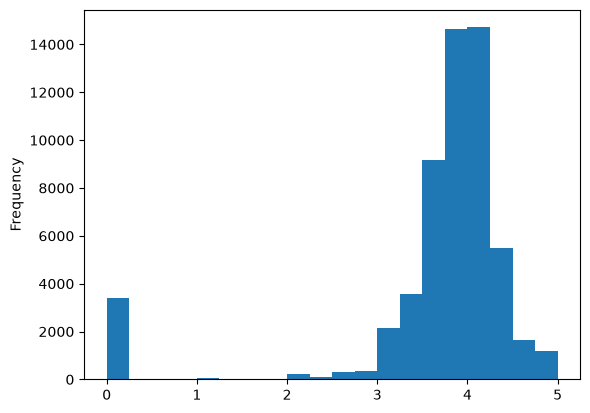

In [12]:
# plot a histogram with 20 bins
# ...

# compute the skewness measure
# skew = ...

# YOUR CODE HERE
data['Rating'].plot.hist(bins=20)
skew = data['Rating'].skew()

print("The skewness measure is {:.3f}.".format(skew))

In [13]:
np.testing.assert_approx_equal(skew, -2.776, 2)
print("---- Horay! Assert passed ---- ")

---- Horay! Assert passed ---- 


## Exercise 5.2 - Kurtosis of the rating distribution

Let's now check the kurtosis for the plotted `Rating` distribution and compare it with a normal distribution with the same characteristics.

We generate a normal distribution for you below:

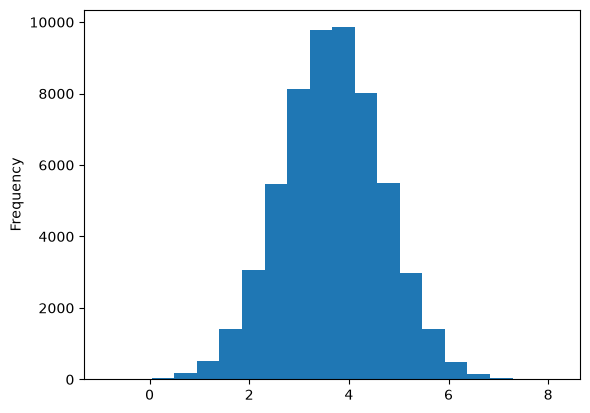

In [15]:
np.random.seed(42) # we set a random seed so all notebooks generate the same random numbers

mean, std, n = (data["Rating"].mean(), 
                data["Rating"].std(), 
                data["Rating"].shape[0])
random_normal_returns = np.random.normal(mean, std, n)  # here, we generate the random normal distribution
data_normal = pd.Series(data=random_normal_returns, index=data.index)

data_normal.plot.hist(bins=20);

In [16]:
# compute the kurtosis measures
# kurt_rating = ...
# kurt_normal = ...

# YOUR CODE HERE
kurt_rating = data['Rating'].kurt()
kurt_normal = data_normal.kurt()

print("The kurtosis measure for the data distribution is {:.1f}.".format(kurt_rating))
print("The kurtosis measure for the random normal distribution is {:.1f}."
      .format(kurt_normal))

The kurtosis measure for the data distribution is 7.5.
The kurtosis measure for the random normal distribution is -0.0.


In [17]:
np.testing.assert_approx_equal(kurt_rating, 7.5, 2, err_msg='The rating kurtosis is not correct.')
np.testing.assert_approx_equal(kurt_normal, 0, 0, err_msg='The normal kurtosis is not correct.')
print("---- Yeah! all asserts passed ---- ")

---- Yeah! all asserts passed ---- 


## Exercise 6 - Quantiles

Find the value of the first, second, and third quartiles of the `Rating` distribution. Find also the value of the mean. Is the second quartile equal to the mean?

In [19]:
# output the quartiles as a pandas series
# quartiles_rating = ...
# mean_rating = ...

# YOUR CODE HERE
quartiles_rating = data['Rating'].quantile([0.25, 0.5, 0.75])
mean_rating = data['Rating'].mean()

In [20]:
assert isinstance(quartiles_rating, pd.Series), 'The quartiles_rating variable should be a pandas series.'
assert _hash(quartiles_rating) == 'f3ded9e818', 'The quartiles values are not correct.'
np.testing.assert_almost_equal(mean_rating, 3.6579095, 3, err_msg='The mean rating is not correct.')
print("---- Yoooo! All asserts passed ---- ")

---- Yoooo! All asserts passed ---- 


## Exercise 7 - Summary stats

There's a pandas method really useful to summarize variables. Do you remember what it is?

Apply the method on the `CountsOfReview` column and investigate the results.

In [21]:
# CountsOfReview_summary ...

# YOUR CODE HERE
CountsOfReview_summary = data['CountsOfReview'].describe()

In [22]:
assert isinstance(CountsOfReview_summary, pd.Series), "Make sure to apply the correct method."
assert _hash(CountsOfReview_summary) == '5acbbe74f6', 'The result is not correct.'

print("---- Weee! All asserts passed ---- ")

---- Weee! All asserts passed ---- 


## Exercise 8 - Outliers and log transformations

Let's focus on the outliers for the `CountsOfReview`. First let's clean up the `CountOfReview` column and check if our data has 0 counts of review:

In [23]:
data.loc[data["CountsOfReview"] == 0].head()

,Name,pagesNumber,Publisher,CountsOfReview,PublishYear,Authors,Rating,ISBN
Id,,,,,,,,
46,Ruby Quickly: Ruby and Rails for the Real World,360,Manning Publications,0,2006,Mark Watson,3.40,1932394745
54,Molly Hatchet - 5 of the Best,56,Cherry Lane Music Company,0,2003,Molly Hatchet,4.33,1575606240
56,The Woodsman and His Hatchet: Eighty Years on ...,150,Stoneydale Press,0,1996,Bud Cheff Sr.,3.60,912299622
108,The Secrets of Frank Herbert's Dune,160,iBooks,0,2000,James Van Hise,3.52,074340730X
131,The Power of One: The Solo Play for Playwright...,240,Heinemann Drama,0,2000,Louis E. Catron,3.67,325001537


There are several `CountsOfReview` with 0. To simplify for now, let's drop these entries.

In [24]:
data_non_zero = data.drop(data.loc[data["CountsOfReview"] == 0].index, axis=0)

How to deal with the outliers?

In the learning notebook, you learned a few ways to deal with the outliers In this exercise, we'll explore the log transformation and see if it helps us in this case.

Do the following:

- Obtain the mean and the median of the `CountsOfReview`; which one is greater?
- Create a new column named `log_CountsOfReview` with the log of `CountsOfReview`;
- Obtain the mean and the median of the `log_CountsOfReview`; are they very different from each other?
- Plot `log_CountsOfReview` using a histogram with 20 bins and compare it with the original distribution.
- What do you think? Were the outliers dealt with?

The CountsOfReview has mean 188 and median 12
The log of the CountsOfReview has mean 2.7 and median 2.5


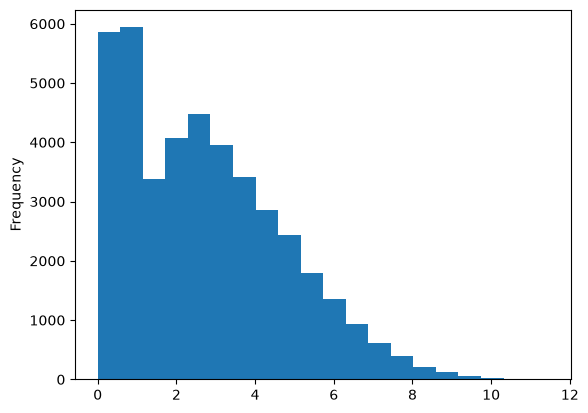

In [25]:
# counts_of_review_mean = ...
# counts_of_review_median = ...
# data_non_zero["log_CountsOfReview"] = ...
# log_counts_of_review_mean = ...
# log_counts_of_review_median = ...

# plot a histogram with 20 bins

# YOUR CODE HERE
counts_of_review_mean = data_non_zero['CountsOfReview'].mean()
counts_of_review_median = data_non_zero['CountsOfReview'].median()
data_non_zero['log_CountsOfReview'] = np.log(data_non_zero['CountsOfReview'])
log_counts_of_review_mean = data_non_zero['log_CountsOfReview'].mean()
log_counts_of_review_median = data_non_zero['log_CountsOfReview'].median()

data_non_zero['log_CountsOfReview'].plot.hist(bins=20)

print('The CountsOfReview has mean %d and median %d' % (
    counts_of_review_mean, counts_of_review_median))
print('The log of the CountsOfReview has mean %0.1f and median %0.1f' % (
    log_counts_of_review_mean, log_counts_of_review_median))

In [26]:
np.testing.assert_almost_equal(counts_of_review_mean, 188.161, decimal=2, err_msg='The mean is not correct.')
np.testing.assert_almost_equal(counts_of_review_median, 12.0, decimal=1, err_msg='The median is not correct.')
np.testing.assert_almost_equal(data_non_zero['log_CountsOfReview'].sum(), 114053.234, decimal=2, 
                               err_msg='The transformed column is not correct.')
np.testing.assert_almost_equal(log_counts_of_review_mean, 2.721, decimal=2, err_msg='The log mean is not correct.')
np.testing.assert_almost_equal(log_counts_of_review_median, 2.484, decimal=2, err_msg='The log median is not correct.')
print("---- You did it!! All asserts passed! ---- ")

---- You did it!! All asserts passed! ---- 


Congratulations! You have finished. Don't forget to [submit your work](https://github.com/LDSSA/batch-students/blob/main/guides/ldssa-workflow.md#34-commit-and-push-the-exercise-notebook-to-your-repo) and good luck with the upcoming SLUs!

![](media/complete.gif)